# Computer Vision Lab Mid: HOG vs SIFT on Blood-Cell Images
**Name:** Hanzala Ajaz  |  **Roll No:** FA23-BAI-016

## Personal Settings
| Setting | Rule | My value |
|---|---|---|
| Random seed | last two digits of reg. no. (016) | **16** |
| HOG cell size | last digit 6 is even | **8 x 8** |
| SIFT grid | last digit 6 is in 5 to 9 | **6 x 6 grid (36 keypoints)** |

In [1]:
# Install the libraries (needed once, e.g. on Google Colab)
!pip install -q medmnist opencv-python scikit-image scikit-learn matplotlib pandas

In [2]:
# ---- PERSONAL SETTINGS: only this cell depends on the registration number ----
REG_NO = "FA23-BAI-016"

last_digit = int(REG_NO[-1])          # last digit  -> 6
SEED = int(REG_NO[-2:])               # last two digits -> 16

HOG_CELL = 8 if last_digit % 2 == 0 else 16     # even -> 8x8, odd -> 16x16
GRID = 4 if last_digit <= 4 else 6              # 0-4 -> 4x4, 5-9 -> 6x6

print("Seed      :", SEED)
print("HOG cell  :", HOG_CELL, "x", HOG_CELL)
print("SIFT grid :", GRID, "x", GRID, "=", GRID * GRID, "keypoints")

Seed      : 16
HOG cell  : 8 x 8
SIFT grid : 6 x 6 = 36 keypoints


In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from medmnist import BloodMNIST

np.random.seed(SEED)   # makes everything repeatable

# Q1. Data Setup

In [4]:
# Fixed settings given in the exam
CLASS_IDS   = [1, 5, 6, 7]                                   # original BloodMNIST labels
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_PER_CLASS = {"train": 100, "val": 30, "test": 30}

def load_split(split, n_per_class):
    """Load one split, keep 4 classes, pick n images per class with our seed,
    convert to grayscale and resize to 128x128."""
    ds = BloodMNIST(split=split, download=True, size=64)
    imgs = ds.imgs                    # shape (N, 64, 64, 3), RGB
    labels = ds.labels.flatten()      # shape (N,)

    rng = np.random.RandomState(SEED) # same seed -> same images every run
    X, y = [], []
    for new_label, class_id in enumerate(CLASS_IDS):    # new labels are 0..3
        idx = np.where(labels == class_id)[0]            # all images of this class
        chosen = rng.choice(idx, n_per_class, replace=False)
        for i in chosen:
            gray = cv2.cvtColor(imgs[i], cv2.COLOR_RGB2GRAY)   # grayscale
            gray = cv2.resize(gray, (128, 128))                # resize to 128x128
            X.append(gray)
            y.append(new_label)
    return np.array(X, dtype=np.uint8), np.array(y)

X_train, y_train = load_split("train", N_PER_CLASS["train"])
X_val,   y_val   = load_split("val",   N_PER_CLASS["val"])
X_test,  y_test  = load_split("test",  N_PER_CLASS["test"])

# Print shape and class counts of each split
for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:5s} | images shape: {X.shape} | labels shape: {y.shape} | class counts: {np.bincount(y).tolist()}")

100%|██████████| 156M/156M [01:46<00:00, 1.47MB/s]


train | images shape: (400, 128, 128) | labels shape: (400,) | class counts: [100, 100, 100, 100]
val   | images shape: (120, 128, 128) | labels shape: (120,) | class counts: [30, 30, 30, 30]
test  | images shape: (120, 128, 128) | labels shape: (120,) | class counts: [30, 30, 30, 30]


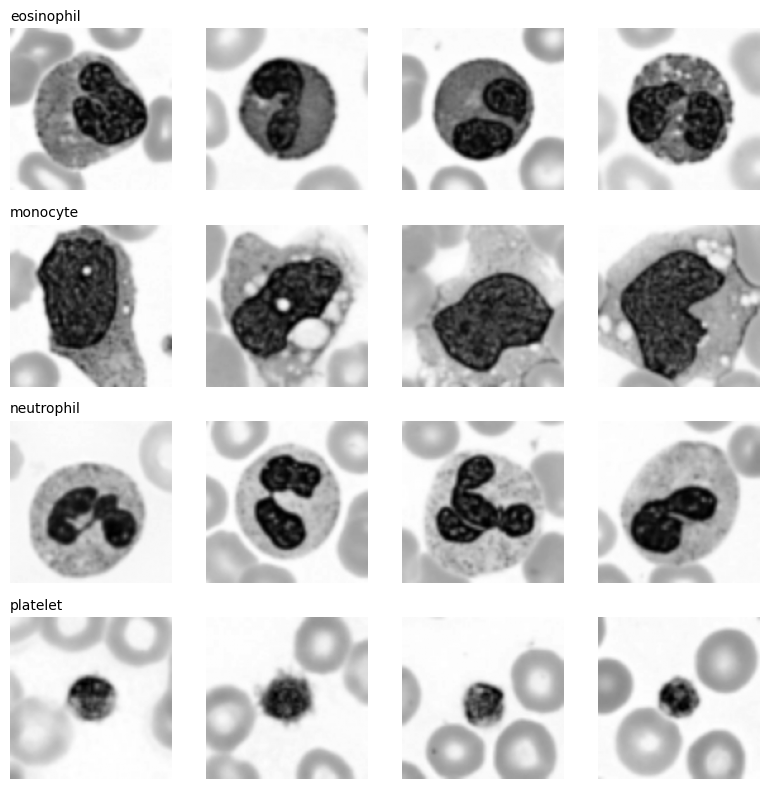

In [5]:
# One grid: 4 example images per class (rows = classes)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for row, cname in enumerate(CLASS_NAMES):
    idx = np.where(y_train == row)[0][:4]      # first 4 images of this class
    for col, i in enumerate(idx):
        axes[row, col].imshow(X_train[i], cmap="gray")
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(cname, fontsize=10, loc="left")
plt.tight_layout()
plt.show()

### Helper functions (used in Q2, Q3 and Q4)
`train_best_svm` tries C = 0.1, 1, 10 and picks the best one **using the validation set only**.

In [6]:
C_VALUES = [0.1, 1, 10]

def train_best_svm(Xtr, ytr, Xva, yva):
    """Train LinearSVC for each C, choose C with the best VALIDATION accuracy."""
    best_model, best_acc, best_C = None, -1, None
    for C in C_VALUES:
        model = LinearSVC(C=C, max_iter=20000, random_state=SEED)
        model.fit(Xtr, ytr)
        acc = accuracy_score(yva, model.predict(Xva))
        print(f"  C = {C:<5} -> validation accuracy = {acc:.4f}")
        if acc > best_acc:                       # strict '>' keeps the smaller C on ties
            best_model, best_acc, best_C = model, acc, C
    print(f"  Best C = {best_C} (val accuracy {best_acc:.4f})")
    return best_model, best_C

def report(model, X, y, title):
    """Print accuracy, macro-F1 and show the confusion matrix."""
    pred = model.predict(X)
    acc = accuracy_score(y, pred)
    f1 = f1_score(y, pred, average="macro")
    cm = confusion_matrix(y, pred)
    print(f"{title}: accuracy = {acc:.4f} | macro-F1 = {f1:.4f}")
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(title)
    plt.show()
    return cm

# Q2. HOG + SVM

In [7]:
# HOG settings: 9 orientations, our cell size, 2x2 cells per block
def hog_features(img):
    return hog(img,
               orientations=9,
               pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2),
               block_norm="L2-Hys",      # block normalisation
               feature_vector=True)

def extract_hog(images):
    return np.array([hog_features(im) for im in images])

Xtr_hog = extract_hog(X_train)
Xva_hog = extract_hog(X_val)

print("HOG feature matrix (train):", Xtr_hog.shape)
print("HOG feature length per image:", Xtr_hog.shape[1])

# Same calculation done with code (to check the hand calculation below)
cells = 128 // HOG_CELL          # cells per side
blocks = cells - 1               # blocks per side (2x2 block slides by 1 cell)
print("Check by formula:", blocks, "*", blocks, "* (2*2) * 9 =", blocks * blocks * 4 * 9)

HOG feature matrix (train): (400, 8100)
HOG feature length per image: 8100
Check by formula: 15 * 15 * (2*2) * 9 = 8100


**Hand calculation of the HOG feature length (cell = 8 x 8):**

1. Image = 128 x 128, cell = 8 x 8, so cells per side = 128 / 8 = **16**, giving 16 x 16 = 256 cells.
2. Each block = 2 x 2 cells and slides by 1 cell, so blocks per side = 16 - 1 = **15**, giving 15 x 15 = **225 blocks**.
3. Each block has 2 x 2 = 4 cells, and each cell has a 9-bin histogram, so values per block = 4 x 9 = **36**.
4. Total length = 225 x 36 = **8100**.

*(If the cell were 16 x 16: 8 cells per side, 7 blocks per side, 49 x 36 = 1764.)*

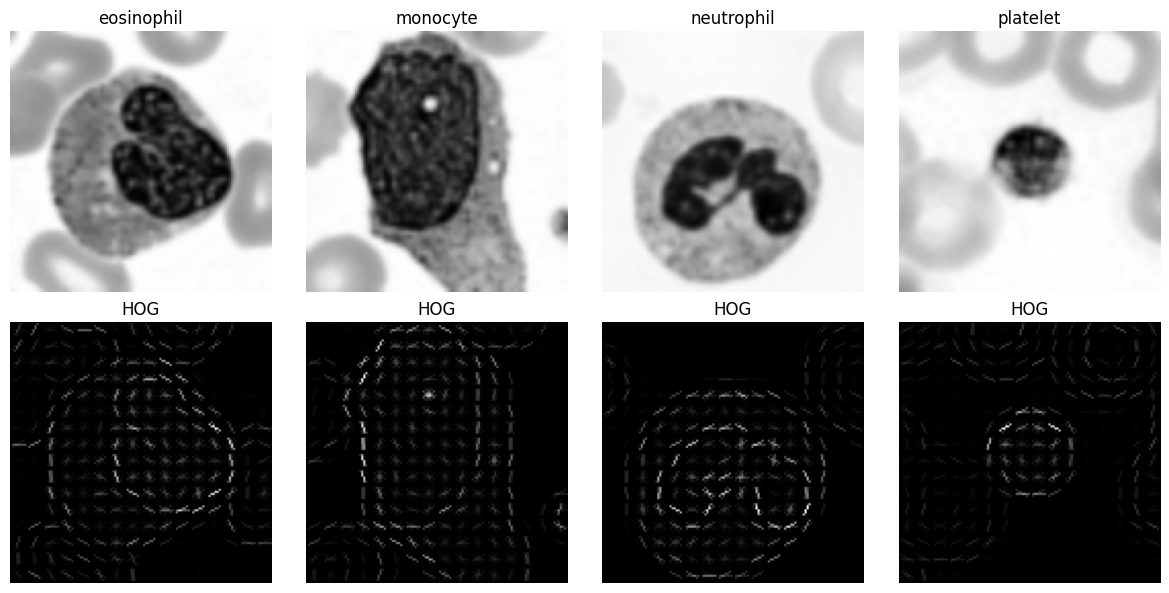

In [8]:
# HOG picture for one image from each class
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for c, cname in enumerate(CLASS_NAMES):
    img = X_train[np.where(y_train == c)[0][0]]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
                     cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() + 1e-6))  # brighter picture
    axes[0, c].imshow(img, cmap="gray");     axes[0, c].set_title(cname); axes[0, c].axis("off")
    axes[1, c].imshow(hog_img, cmap="gray"); axes[1, c].set_title("HOG");  axes[1, c].axis("off")
plt.tight_layout()
plt.show()

Training HOG + SVM:
  C = 0.1   -> validation accuracy = 0.7000
  C = 1     -> validation accuracy = 0.7000
  C = 10    -> validation accuracy = 0.7000
  Best C = 0.1 (val accuracy 0.7000)
HOG + SVM (validation): accuracy = 0.7000 | macro-F1 = 0.6997


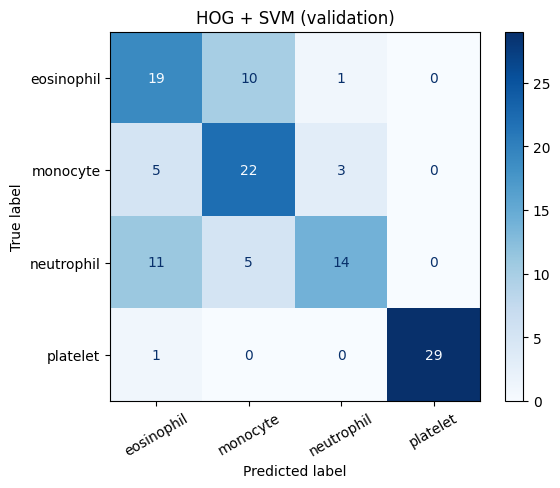

In [9]:
# Train HOG + SVM (choose C on the validation set)
print("Training HOG + SVM:")
hog_model, hog_C = train_best_svm(Xtr_hog, y_train, Xva_hog, y_val)

# Validation accuracy, macro-F1 and confusion matrix
cm_hog_val = report(hog_model, Xva_hog, y_val, "HOG + SVM (validation)")

# Q3. SIFT + SVM

### Q3(a). Normal SIFT detection

Average keypoints per image: 71.84
Minimum keypoints per image: 9
Maximum keypoints per image: 167
Images with ZERO keypoints : 0


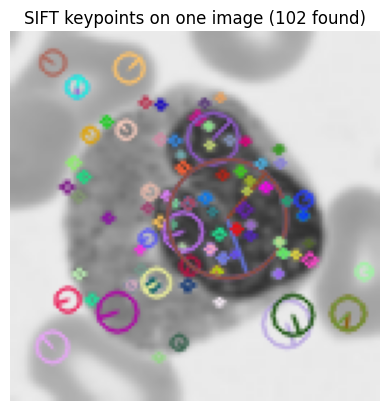

In [10]:
sift = cv2.SIFT_create()

kp_counts = []
for img in X_train:
    keypoints, descriptors = sift.detectAndCompute(img, None)   # SIFT decides where keypoints are
    kp_counts.append(len(keypoints))
kp_counts = np.array(kp_counts)

print("Average keypoints per image:", round(kp_counts.mean(), 2))
print("Minimum keypoints per image:", kp_counts.min())
print("Maximum keypoints per image:", kp_counts.max())
print("Images with ZERO keypoints :", int((kp_counts == 0).sum()))

# Draw the detected keypoints on one image
img = X_train[0]
keypoints, _ = sift.detectAndCompute(img, None)
img_kp = cv2.drawKeypoints(img, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(img_kp, cmap="gray")
plt.title(f"SIFT keypoints on one image ({len(keypoints)} found)")
plt.axis("off")
plt.show()

**Why is a different number of keypoints per image a problem for an SVM?**
An SVM needs every image to have a feature vector of the **same length**. Each keypoint gives a 128-number descriptor, so images with different keypoint counts give vectors of different sizes (and some images may have none), which the SVM cannot take as input.

### Q3(b). Fix: fixed grid of keypoints

In [11]:
def make_grid_keypoints(grid=GRID, size=32, img_size=128):
    """Place keypoints on a regular grid (same places for every image)."""
    step = img_size / grid                       # distance between grid points
    kps = []
    for row in range(grid):
        for col in range(grid):
            x = (col + 0.5) * step               # centre of each grid cell
            y = (row + 0.5) * step
            kps.append(cv2.KeyPoint(float(x), float(y), size, 0))   # (x, y, size, angle=0)
    return kps

grid_kps = make_grid_keypoints()
print("Number of grid keypoints:", len(grid_kps))

def sift_grid_features(img):
    """Compute SIFT descriptor at every grid point and join them into ONE vector."""
    _, desc = sift.compute(img, grid_kps)        # desc shape = (grid*grid, 128)
    return desc.flatten() / 255.0                # flatten + scale so the SVM trains faster

def extract_sift(images):
    return np.array([sift_grid_features(im) for im in images])

Xtr_sift = extract_sift(X_train)
Xva_sift = extract_sift(X_val)

print("SIFT feature matrix (train):", Xtr_sift.shape)
print("SIFT feature length per image:", Xtr_sift.shape[1])
print("Check by formula:", GRID * GRID, "* 128 =", GRID * GRID * 128)

Number of grid keypoints: 36
SIFT feature matrix (train): (400, 4608)
SIFT feature length per image: 4608
Check by formula: 36 * 128 = 4608


**Hand calculation of the SIFT feature length (6 x 6 grid):**

1. Grid points = 6 x 6 = **36** keypoints (same positions on every image).
2. Each SIFT descriptor has **128** numbers.
3. Total length = 36 x 128 = **4608** for every image.

*(For a 4 x 4 grid it would be 16 x 128 = 2048.)*

### Q3(c). Train SIFT + SVM

Training SIFT + SVM:
  C = 0.1   -> validation accuracy = 0.8083
  C = 1     -> validation accuracy = 0.8083


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


  C = 10    -> validation accuracy = 0.7917
  Best C = 0.1 (val accuracy 0.8083)
SIFT + SVM (validation): accuracy = 0.8083 | macro-F1 = 0.8077


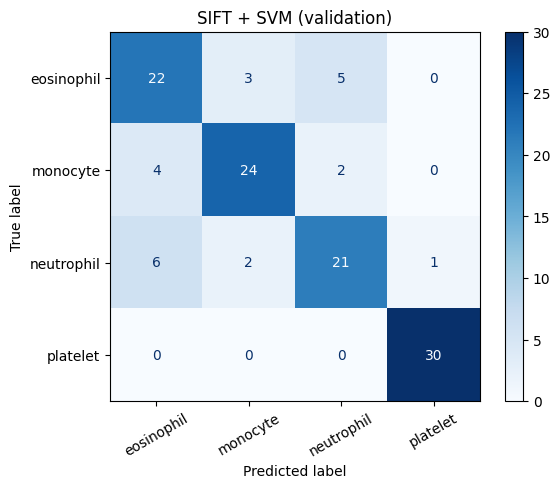

In [12]:
# Train SIFT + SVM (choose C on the validation set)
print("Training SIFT + SVM:")
sift_model, sift_C = train_best_svm(Xtr_sift, y_train, Xva_sift, y_val)

# Validation accuracy, macro-F1 and confusion matrix
cm_sift_val = report(sift_model, Xva_sift, y_val, "SIFT + SVM (validation)")

# Q4. Robustness

### Q4(a). Prediction (written BEFORE running the test)
*(Edit this in your own words before you run the cells below.)*

- **Rotation:** I think **HOG** will lose more accuracy. HOG stores gradient directions in fixed cells, so rotating the cell changes the orientation bins and the spatial layout of the vector.
- **Noise:** I think **HOG** will lose more accuracy. HOG is built from raw gradients, and noise creates many random strong gradients, while SIFT smooths the image and normalises the descriptor.

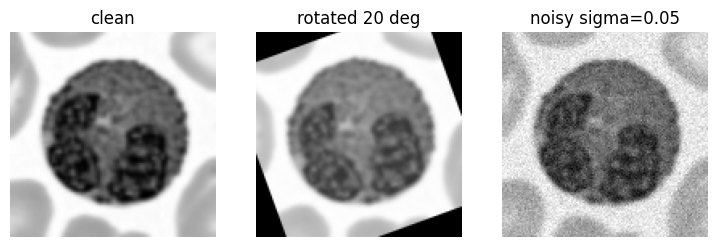

In [13]:
# Both models are now FROZEN (no more training). We only call .predict().
# The test set is used for the first time here.

def rotate_img(img, angle=20):
    """Rotate image by 20 degrees around its centre (size stays 128x128)."""
    M = cv2.getRotationMatrix2D((64, 64), angle, 1.0)
    return cv2.warpAffine(img, M, (128, 128))

def add_noise(img, rng, sigma=0.05):
    """Gaussian noise with sigma=0.05 on an image scaled to 0..1."""
    x = img / 255.0                                  # scale to 0..1
    x = x + rng.normal(0, sigma, img.shape)          # add noise
    x = np.clip(x, 0, 1)                             # keep valid range
    return np.round(x * 255).astype(np.uint8)        # back to 0..255

# Build the three test versions ONCE, so both models see the same images
rng = np.random.RandomState(SEED)
X_test_clean   = X_test
X_test_rotated = np.array([rotate_img(im) for im in X_test])
X_test_noisy   = np.array([add_noise(im, rng) for im in X_test])

# Quick visual check that the changes were applied
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, t in zip(axes, [X_test_clean[0], X_test_rotated[0], X_test_noisy[0]],
                     ["clean", "rotated 20 deg", "noisy sigma=0.05"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.show()

In [14]:
# The change is applied to the images BEFORE feature extraction
cases = {"Clean": X_test_clean, "Rotated": X_test_rotated, "Noisy": X_test_noisy}

results = {"HOG + SVM": {}, "SIFT + SVM": {}}
for case_name, imgs in cases.items():
    results["HOG + SVM"][case_name]  = accuracy_score(y_test, hog_model.predict(extract_hog(imgs)))
    results["SIFT + SVM"][case_name] = accuracy_score(y_test, sift_model.predict(extract_sift(imgs)))

table = pd.DataFrame(results).T
table.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
table["Drop (rotation)"] = table["Clean accuracy"] - table["Rotated accuracy"]
table["Drop (noise)"]    = table["Clean accuracy"] - table["Noisy accuracy"]
table.round(4)

,Clean accuracy,Rotated accuracy,Noisy accuracy,Drop (rotation),Drop (noise)
HOG + SVM,0.7583,0.7167,0.5083,0.0417,0.2500
SIFT + SVM,0.8167,0.5417,0.8250,0.2750,-0.0083


### Q4(c). Was my prediction correct?
*(Fill this in AFTER looking at the table above. Use your own numbers and keep it to 3 sentences.)*

1. Under rotation, HOG went from `___` to `___` (drop `___`) and SIFT went from `___` to `___` (drop `___`), so my prediction was `correct / wrong`.
2. Under noise, HOG went from `___` to `___` (drop `___`) and SIFT went from `___` to `___` (drop `___`), so my prediction was `correct / wrong`.
3. This is because `(one reason that matches your numbers)`.

# Q5. Short Answers and AI Log

**(a) Why does HOG use block normalisation?**
Gradient strength changes with lighting and contrast, so the same cell can give very different histogram values in a bright or dark image. Normalising each block (group of cells) makes the features depend on the local pattern instead of the brightness, so the descriptor is more stable.

**(b) Why is it wrong to choose C using the test set?**
The test set must act like new, unseen data. If we pick C by looking at test accuracy, the model is tuned to the test set, so the test accuracy becomes too optimistic and no longer shows true performance. That is why C is chosen on the validation set and the test set is used only once, at the end.

In [15]:
# Find the two classes confused most (clean test set, both models added together)
cm_hog_test  = confusion_matrix(y_test, hog_model.predict(extract_hog(X_test_clean)))
cm_sift_test = confusion_matrix(y_test, sift_model.predict(extract_sift(X_test_clean)))

cm_total = cm_hog_test + cm_sift_test
np.fill_diagonal(cm_total, 0)                     # ignore correct predictions
true_c, pred_c = np.unravel_index(np.argmax(cm_total), cm_total.shape)

print("HOG test confusion matrix:\n", cm_hog_test)
print("SIFT test confusion matrix:\n", cm_sift_test)
print(f"\nMost confused pair: true '{CLASS_NAMES[true_c]}' predicted as '{CLASS_NAMES[pred_c]}' "
      f"({cm_total[true_c, pred_c]} mistakes in total)")

HOG test confusion matrix:
 [[18  3  8  1]
 [ 5 23  2  0]
 [ 6  4 20  0]
 [ 0  0  0 30]]
SIFT test confusion matrix:
 [[21  4  5  0]
 [ 4 24  2  0]
 [ 6  1 23  0]
 [ 0  0  0 30]]

Most confused pair: true 'eosinophil' predicted as 'neutrophil' (13 mistakes in total)


**Which two classes were confused most, and why might grayscale make this harder?**
*(Fill in the pair from the output above.)* The models confused `______` and `______` most (see the confusion matrices above).
In colour images, cell types like eosinophils and neutrophils are separated partly by stain colour (eosinophil granules are bright red/pink, neutrophil nuclei are purple). After converting to grayscale, these colour differences turn into similar grey levels, so the models have only shape and texture left, and cells with similar size and shape look alike.

**AI log**

| Prompt (one line) | What I changed | How I checked it was correct |
|---|---|---|
| "Give complete simple code for the HOG vs SIFT lab mid exam with comments" | Set my seed/cell/grid from my roll number, rewrote my own prediction and explanations | Printed shapes and class counts, matched HOG length (8100) and SIFT length (4608) with my hand calculation, looked at the HOG picture and keypoint picture |